# BRD4 BD1/BD2 protonation audit — executed analysis

PROPKA 3.5.1 predictions supplied from CHPC for ligand-free 2YEL chain A (BD1) and 2YEM chain B (BD2). This notebook reproduces the post-processing and displays the archived publication figures. The original PROPKA runs were performed on CHPC; raw `.pka` files are not included here. Estimated fractions use the independent-site Henderson–Hasselbalch approximation; folding energies are relative predictions, not measured binding or folding energies.

In [1]:
from pathlib import Path
import csv
import math
from IPython.display import SVG, display

root = Path.cwd()
pH_values = (7.0, 7.4, 7.5)
with (root / "histidine_protonation.csv").open() as f:
    hist = list(csv.DictReader(f))
with (root / "folding_free_energy.csv").open() as f:
    folding = list(csv.DictReader(f))
assert len(hist) == 15 and len(folding) == 15
print("Histidine observations:", len(hist))
print("Folding-energy observations:", len(folding))

Histidine observations: 15
Folding-energy observations: 15


In [2]:
def protonated_percent(ph, pka):
    return 100 / (1 + 10 ** (ph - pka))

print(f"{'Residue':<13} {'pKa':>5} {'pH 7.0':>9} {'pH 7.4':>9} {'pH 7.5':>9}")
for name in dict.fromkeys(r['Residue'] for r in hist):
    rows = [r for r in hist if r['Residue'] == name]
    pka = float(rows[0]['Predicted_pKa'])
    fractions = [protonated_percent(ph, pka) for ph in pH_values]
    assert all(abs(v - float(r['Estimated_protonated_fraction_percent'])) < 0.02 for v, r in zip(fractions, rows))
    print(f"{name:<13} {pka:5.2f}" + ''.join(f" {v:8.2f}" for v in fractions))
print("All five histidines are predominantly neutral at all three pH values.")

Residue         pKa    pH 7.0    pH 7.4    pH 7.5
BD1 His77      5.77     5.56     2.29     1.83
BD2 His369     6.45    21.99    10.09     8.18
BD2 His388     6.40    20.08     9.09     7.36
BD2 His396     6.24    14.81     6.47     5.21
BD2 His437     6.27    15.70     6.90     5.56
All five histidines are predominantly neutral at all three pH values.


In [3]:
print(f"{'pH':>3} {'BD1 [kcal/mol]':>16} {'BD2 [kcal/mol]':>16}")
for r in folding:
    print(f"{int(r['pH']):3d} {float(r['BD1_kcal_mol']):16.2f} {float(r['BD2_kcal_mol']):16.2f}")
for domain in ('BD1', 'BD2'):
    best = min(folding, key=lambda r: float(r[domain + '_kcal_mol']))
    print(f"{domain}: minimum on integer-pH grid = {float(best[domain + '_kcal_mol']):.2f} kcal/mol at pH {best['pH']}")
print('Original PROPKA summaries report an optimum stability pH of 7.8 for both domains.')

 pH   BD1 [kcal/mol]   BD2 [kcal/mol]
  0             7.47             0.57
  1             7.44             0.54
  2             7.18             0.25
  3             5.93            -1.56
  4             3.83            -5.71
  5             3.43            -8.46
  6             3.31            -9.25
  7             2.90            -9.79
  8             2.82            -9.93
  9             3.61            -8.71
 10             7.09            -4.23
 11            14.81             3.37
 12            23.33             9.60
 13            28.95            13.74
 14            32.03            16.69
BD1: minimum on integer-pH grid = 2.82 kcal/mol at pH 8
BD2: minimum on integer-pH grid = -9.93 kcal/mol at pH 8
Original PROPKA summaries report an optimum stability pH of 7.8 for both domains.


In [4]:
import shutil
import subprocess
import sys
import tempfile

# Regenerate the publication outputs in a temporary directory,
# leaving the archived source figures unchanged.
with tempfile.TemporaryDirectory() as tmp:
    tmp = Path(tmp)
    shutil.copy2(root / "plot_propka.py", tmp / "plot_propka.py")
    subprocess.run([sys.executable, str(tmp / "plot_propka.py")], check=True)
    outputs = sorted(p.name for p in tmp.iterdir() if p.suffix in {".png", ".pdf", ".svg", ".csv"})
    assert len(outputs) == 8
    print("Regenerated outputs:")
    print("\n".join(outputs))

Regenerated outputs:
Fig1_Histidine_protonation.pdf
Fig1_Histidine_protonation.png
Fig1_Histidine_protonation.svg
Fig2_Folding_free_energy.pdf
Fig2_Folding_free_energy.png
Fig2_Folding_free_energy.svg
folding_free_energy.csv
histidine_protonation.csv


## Publication figures

Archived vector figures: 130 × 100 mm; white background; bold DejaVu Sans labels and legends.

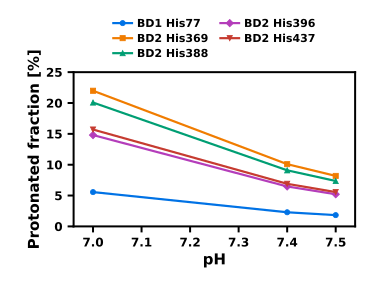

In [5]:
display(SVG(filename=str(root / "Fig1_Histidine_protonation.svg")))

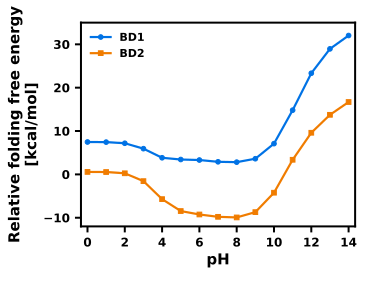

In [6]:
display(SVG(filename=str(root / "Fig2_Folding_free_energy.svg")))

## Interpretation

The five histidines have predicted pKa values below 7.0. The three candidate pH values do not change their predominant charge state, but the estimated protonated fractions differ. These apo-protein predictions do not determine histidine tautomer orientation, ligand microstates, or optimal binding pH. The original summary reports pH 7.8 as an optimum for relative folding stability, not binding affinity. Final receptor preparation and redocking remain separate validation steps.

To regenerate the PNG (600 DPI), PDF and SVG figures, run `python plot_propka.py` in this directory.